# Predicción de enfermedad cardiaca con Random Forest

**Inteligencia Artificial I · Actividad 3**
Integrantes: Juan Supelano · pipereinaa · Edwinvas178-bot

Objetivo: entrenar dos clasificadores Random Forest con el *Heart Failure Prediction Dataset*:

| Modelo | Variables | Usuario |
|---|---|---|
| **Rápido** | 7 (edad, sexo, síntomas, presión, colesterol, glucosa) | Cualquier persona |
| **Completo** | 11 (incluye ECG y prueba de esfuerzo) | Personal de salud |

La comparación entre los dos muestra cuánta precisión se pierde al quitar los datos clínicos.

## 1. Carga y exploración de datos

In [1]:
import sys, json, warnings
from datetime import date
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from src.preprocessing import (load_raw, clean, build_pipeline, FEATURES_FULL,
                               FEATURES_QUICK, CATEGORICAL, NUMERIC, TARGET)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
IMG = '../app/static/img/'   # las figuras se reutilizan en la página "El modelo"

df = load_raw('../data/raw/heart.csv')
print(f'Registros: {df.shape[0]} | Columnas: {df.shape[1]}')
df.head()

Registros: 918 | Columnas: 12


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       917 non-null    float64
 4   Cholesterol     746 non-null    float64
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 86.2 KB


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,917.0,132.54,18.00,80.0,120.00,130.0,140.0,200.0
Cholesterol,746.0,244.64,59.15,85.0,207.25,237.0,275.0,603.0
FastingBS,918.0,0.23,0.42,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.55,0.50,0.0,0.00,1.0,1.0,1.0


**Diccionario de variables**

| Variable | Descripción |
|---|---|
| Age | Edad en años |
| Sex | M / F |
| ChestPainType | TA angina típica, ATA angina atípica, NAP dolor no anginoso, ASY asintomático |
| RestingBP | Presión arterial en reposo (mmHg) |
| Cholesterol | Colesterol sérico (mg/dL) |
| FastingBS | 1 si la glucosa en ayunas > 120 mg/dL |
| RestingECG | Normal, ST (anomalía ST-T), LVH (hipertrofia ventricular izquierda) |
| MaxHR | Frecuencia cardiaca máxima alcanzada |
| ExerciseAngina | Angina inducida por ejercicio (Y/N) |
| Oldpeak | Depresión del segmento ST |
| ST_Slope | Pendiente del ST en el pico del ejercicio (Up, Flat, Down) |
| **HeartDisease** | **Variable objetivo: 1 enfermedad cardiaca, 0 normal** |

## 2. Análisis exploratorio (EDA)
### 2.1 Valores nulos y valores imposibles

In [4]:
print('Nulos por columna:')
print(df.isna().sum().to_string())
print()
print('Registros con valor 0:')
print((df[['RestingBP', 'Cholesterol']] == 0).sum().to_string())

Nulos por columna:
Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0

Registros con valor 0:
RestingBP      0
Cholesterol    0


`Cholesterol` tiene 172 vacíos y `RestingBP` 1. En el CSV original de Kaggle estos faltantes venían como **0**,
un valor fisiológicamente imposible; en nuestra copia ya están como vacíos. La función `clean()` convierte los
ceros a `NaN` por si se usa el archivo original, y el pipeline los imputa con la mediana. Es el mismo mecanismo
que usa la app cuando el usuario responde "No sé".

### 2.2 Variable objetivo

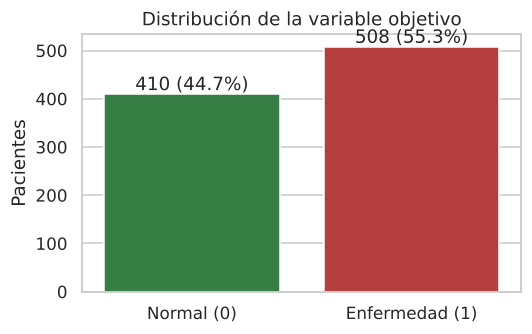

In [5]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
sns.barplot(x=['Normal (0)', 'Enfermedad (1)'], y=counts.values, ax=ax, palette=['#2b8a3e', '#c92a2a'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, f'{v} ({v / len(df):.1%})', ha='center')
ax.set_ylabel('Pacientes'); ax.set_title('Distribución de la variable objetivo')
plt.tight_layout(); plt.show()

Las clases están razonablemente balanceadas, así que *accuracy* es una métrica válida; igual se reportan precision, recall, F1 y ROC-AUC.

### 2.3 Distribución de variables numéricas

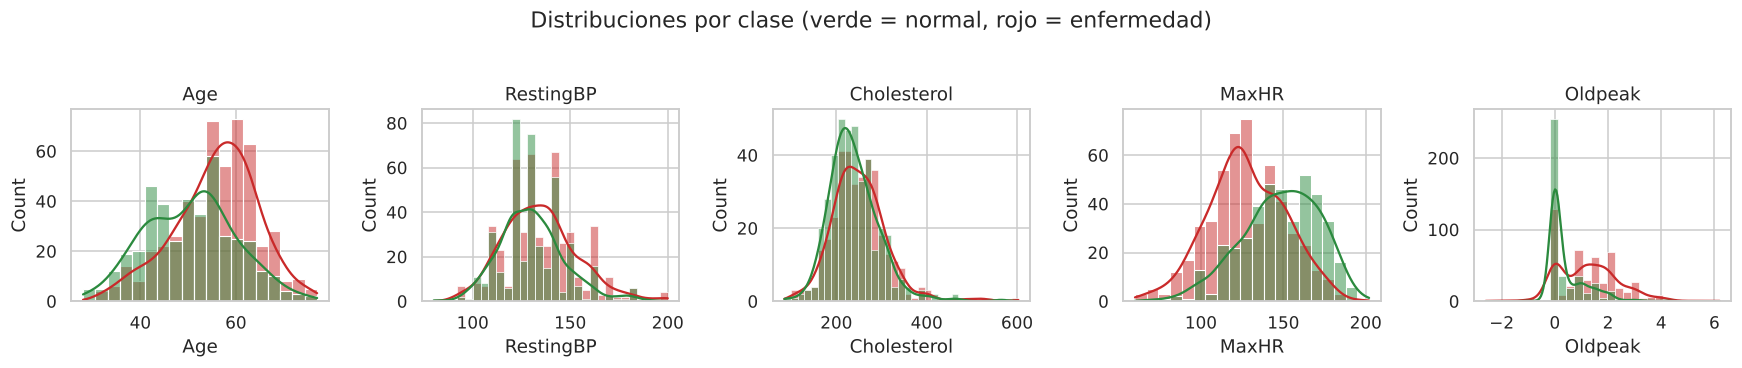

In [6]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df[df[col] != 0] if col in ('RestingBP', 'Cholesterol') else df,
                 x=col, hue=TARGET, kde=True, ax=ax, palette=['#2b8a3e', '#c92a2a'], legend=False)
    ax.set_title(col)
fig.suptitle('Distribuciones por clase (verde = normal, rojo = enfermedad)', y=1.04)
plt.tight_layout(); plt.show()

### 2.4 Variables categóricas frente a la variable objetivo

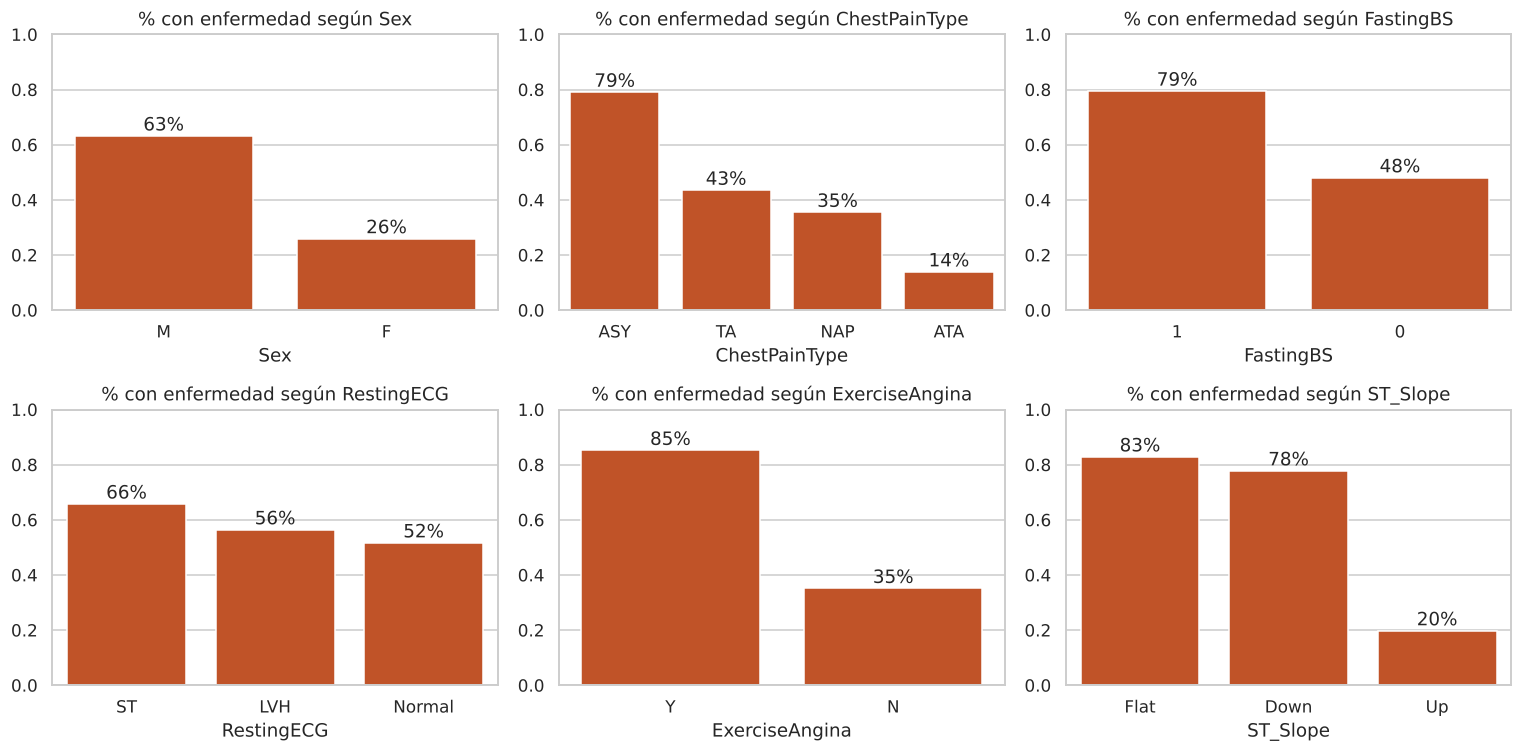

In [7]:
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)[TARGET].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color='#d9480f')
    ax.set_ylim(0, 1); ax.set_title(f'% con enfermedad según {col}'); ax.set_ylabel('')
    for i, v in enumerate(rate.values):
        ax.text(i, v + .02, f'{v:.0%}', ha='center')
plt.tight_layout(); plt.show()

Observaciones:
- **ST_Slope plana**, **angina con ejercicio** y **dolor tipo ASY** tienen tasas de enfermedad muy altas.
- Que *asintomático* (ASY) sea el grupo de mayor riesgo parece raro, pero tiene explicación: son pacientes
  que llegaron al estudio por otra razón clínica y no presentaban dolor típico (isquemia silente).
- Los hombres tienen una tasa bastante mayor que las mujeres.

### 2.5 Correlaciones

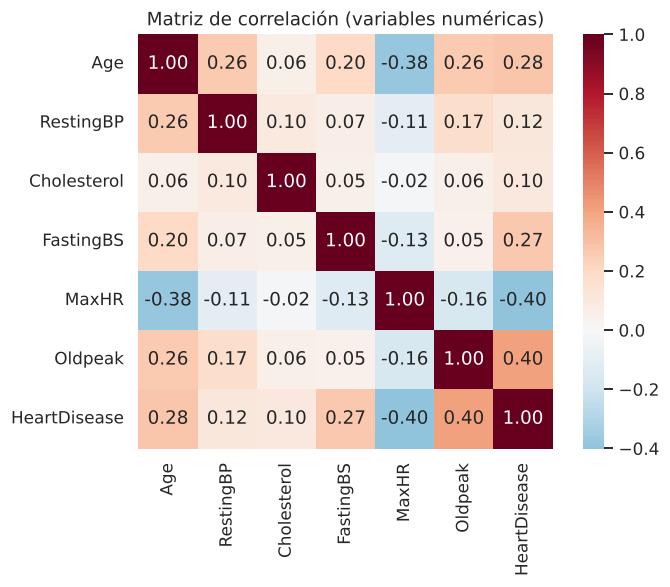

In [8]:
corr = clean(df)[NUMERIC + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, square=True)
ax.set_title('Matriz de correlación (variables numéricas)')
plt.tight_layout(); plt.show()

Ninguna pareja de variables tiene una correlación tan alta como para ser redundante. Oldpeak (+) y MaxHR (−) son las numéricas más relacionadas con la enfermedad.

### 2.6 Outliers

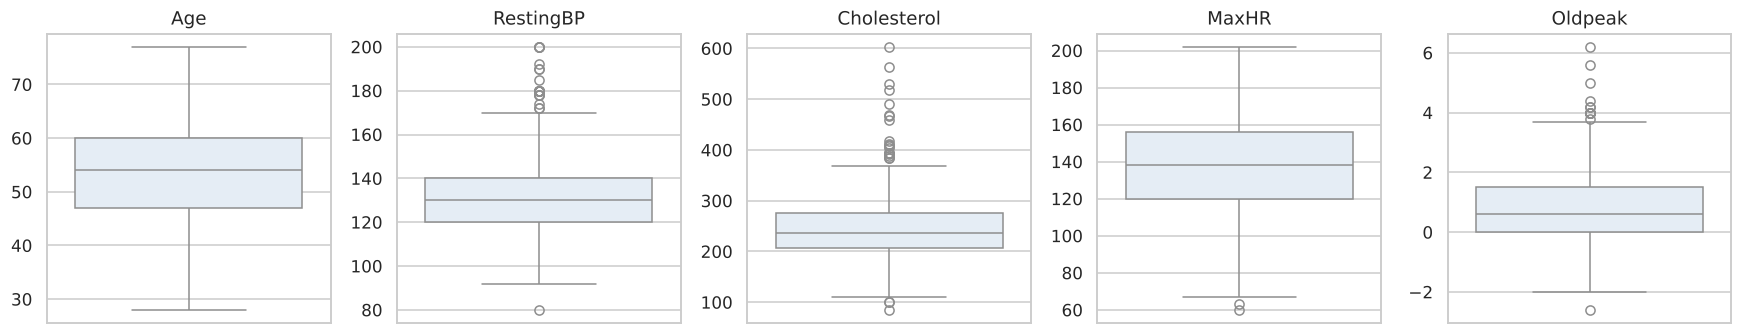

Outliers por criterio IQR:
Age             0
RestingBP      27
Cholesterol    23
MaxHR           2
Oldpeak        16


In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=clean(df)[col], ax=ax, color='#e3edf7')
    ax.set_title(col); ax.set_ylabel('')
plt.tight_layout(); plt.show()

q1, q3 = df[num_cols].quantile([.25, .75]).values
iqr = q3 - q1
outliers = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
print('Outliers por criterio IQR:'); print(outliers.to_string())

Los valores extremos (colesterol de 500+, presión de 200) son clínicamente posibles, así que **no se eliminan**.
Random Forest es robusto frente a outliers porque divide por umbrales y no por distancias.

## 3. Preprocesamiento

In [10]:
from sklearn.model_selection import train_test_split

data = clean(df)
data.to_csv('../data/processed/heart_clean.csv', index=False)

X = data.drop(columns=TARGET)
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

pd.concat([X_train, y_train], axis=1).to_csv('../data/processed/train.csv', index=False)
pd.concat([X_test, y_test], axis=1).to_csv('../data/processed/test.csv', index=False)
print(f'Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}')
print(f'Colesterol faltante en train: {X_train.Cholesterol.isna().sum()}')

Entrenamiento: 734 | Prueba: 184
Colesterol faltante en train: 129


El preprocesamiento está dentro de un `Pipeline` de scikit-learn (`src/preprocessing.py`):

1. **Imputación**: mediana para numéricas, moda para categóricas.
2. **One-hot encoding** para las categóricas.
3. **Sin escalado**: Random Forest no lo necesita porque compara cada variable contra un umbral.

Como el imputador se ajusta solo con los datos de entrenamiento, no hay fuga de información hacia el conjunto de prueba.

## 4. Entrenamiento del modelo
### 4.1 Comparación rápida con otros algoritmos (validación cruzada, 11 variables)

In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from src.preprocessing import build_preprocessor

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidatos = {
    'Regresión logística': Pipeline([('prep', build_preprocessor(FEATURES_FULL)),
                                     ('sc', StandardScaler()), ('m', LogisticRegression(max_iter=1000))]),
    'Árbol de decisión': Pipeline([('prep', build_preprocessor(FEATURES_FULL)),
                                   ('m', DecisionTreeClassifier(random_state=42))]),
    'Random Forest': build_pipeline(FEATURES_FULL),
}
comparacion = {n: cross_val_score(m, X_train[FEATURES_FULL], y_train, cv=cv, scoring='accuracy')
               for n, m in candidatos.items()}
pd.DataFrame({n: {'accuracy media': s.mean(), 'desv. estándar': s.std()}
              for n, s in comparacion.items()}).T.round(3)

,accuracy media,desv. estándar
Regresión logística,0.847,0.030
Árbol de decisión,0.798,0.059
Random Forest,0.849,0.035


Random Forest y la regresión logística quedan prácticamente empatados (≈85 % de accuracy), y ambos superan al árbol de
decisión individual (≈80 %, con más varianza entre folds). Random Forest promedia muchos árboles entrenados con muestras
y variables distintas, lo que reduce el sobreajuste de un solo árbol. Además captura interacciones no lineales sin
transformar las variables y permite explicar cada predicción, que es lo que muestra la app.

### 4.2 Búsqueda de hiperparámetros (GridSearchCV)

In [12]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'rf__n_estimators': [200, 400],
    'rf__max_depth': [None, 6, 10],
    'rf__min_samples_leaf': [1, 3, 5],
    'rf__max_features': ['sqrt', 0.5],
}
modelos, busquedas = {}, {}
for nombre, feats in [('rapido', FEATURES_QUICK), ('completo', FEATURES_FULL)]:
    gs = GridSearchCV(build_pipeline(feats, n_jobs=1), param_grid, cv=cv,
                      scoring='roc_auc', n_jobs=-1)
    gs.fit(X_train[feats], y_train)
    busquedas[nombre] = gs
    modelos[nombre] = gs.best_estimator_
    print(f'{nombre:9s} ROC-AUC CV = {gs.best_score_:.3f} | mejores parámetros: {gs.best_params_}')

rapido    ROC-AUC CV = 0.875 | mejores parámetros: {'rf__max_depth': 6, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 3, 'rf__n_estimators': 200}
completo  ROC-AUC CV = 0.932 | mejores parámetros: {'rf__max_depth': 10, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 5, 'rf__n_estimators': 400}


## 5. Evaluación en el conjunto de prueba

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

FEATS = {'rapido': FEATURES_QUICK, 'completo': FEATURES_FULL}
resultados = {}
for nombre, modelo in modelos.items():
    Xt = X_test[FEATS[nombre]]
    pred = modelo.predict(Xt)
    proba = modelo.predict_proba(Xt)[:, 1]
    cv_acc = cross_val_score(modelo, X_train[FEATS[nombre]], y_train, cv=cv, scoring='accuracy')
    resultados[nombre] = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, proba),
        'cv_accuracy_mean': cv_acc.mean(),
        'cv_accuracy_std': cv_acc.std(),
    }
tabla = pd.DataFrame(resultados).round(3)
tabla.columns = ['Rápido (7 var.)', 'Completo (11 var.)']
tabla

,Rápido (7 var.),Completo (11 var.)
accuracy,0.804,0.897
precision,0.837,0.888
recall,0.804,0.931
f1,0.820,0.909
roc_auc,0.899,0.928
cv_accuracy_mean,0.789,0.854
cv_accuracy_std,0.039,0.036


In [14]:
for nombre, modelo in modelos.items():
    print(f'=== Modelo {nombre} ===')
    print(classification_report(y_test, modelo.predict(X_test[FEATS[nombre]]),
                                target_names=['Normal', 'Enfermedad'], digits=3))

=== Modelo rapido ===
              precision    recall  f1-score   support

      Normal      0.767     0.805     0.786        82
  Enfermedad      0.837     0.804     0.820       102

    accuracy                          0.804       184
   macro avg      0.802     0.804     0.803       184
weighted avg      0.806     0.804     0.805       184

=== Modelo completo ===
              precision    recall  f1-score   support

      Normal      0.909     0.854     0.881        82
  Enfermedad      0.888     0.931     0.909       102

    accuracy                          0.897       184
   macro avg      0.898     0.893     0.895       184
weighted avg      0.897     0.897     0.896       184



### 5.1 Matrices de confusión

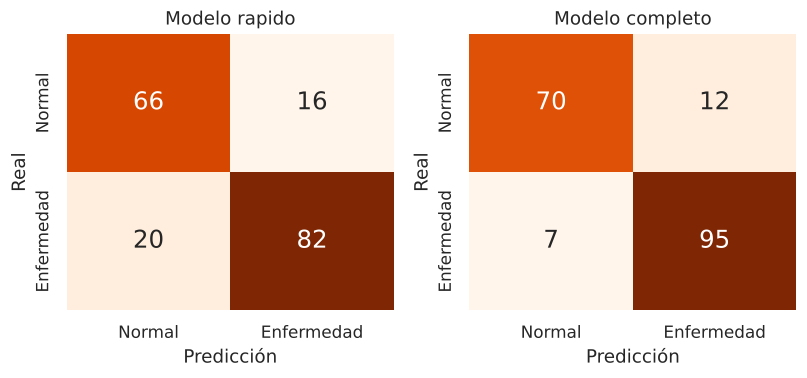

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    cm = confusion_matrix(y_test, modelo.predict(X_test[FEATS[nombre]]))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax,
                xticklabels=['Normal', 'Enfermedad'], yticklabels=['Normal', 'Enfermedad'],
                annot_kws={'size': 16})
    ax.set_title(f'Modelo {nombre}'); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig(IMG + 'confusion_matrices.png', bbox_inches='tight'); plt.show()

### 5.2 Curvas ROC

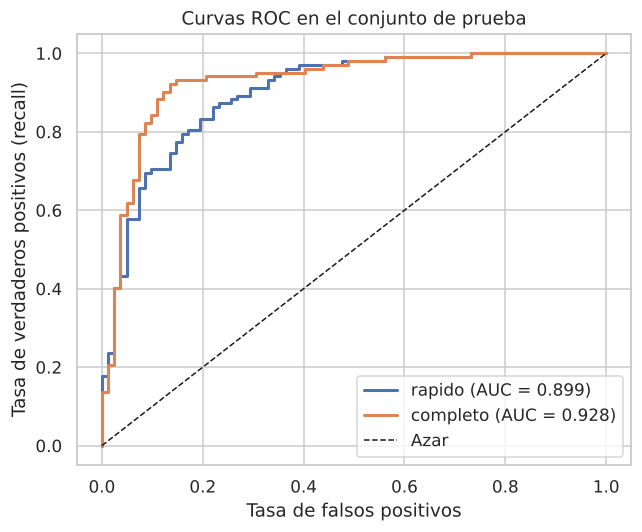

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
for nombre, modelo in modelos.items():
    proba = modelo.predict_proba(X_test[FEATS[nombre]])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {resultados[nombre]["roc_auc"]:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos (recall)')
ax.set_title('Curvas ROC en el conjunto de prueba'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(IMG + 'roc_curves.png', bbox_inches='tight'); plt.show()

### 5.3 Importancia de variables

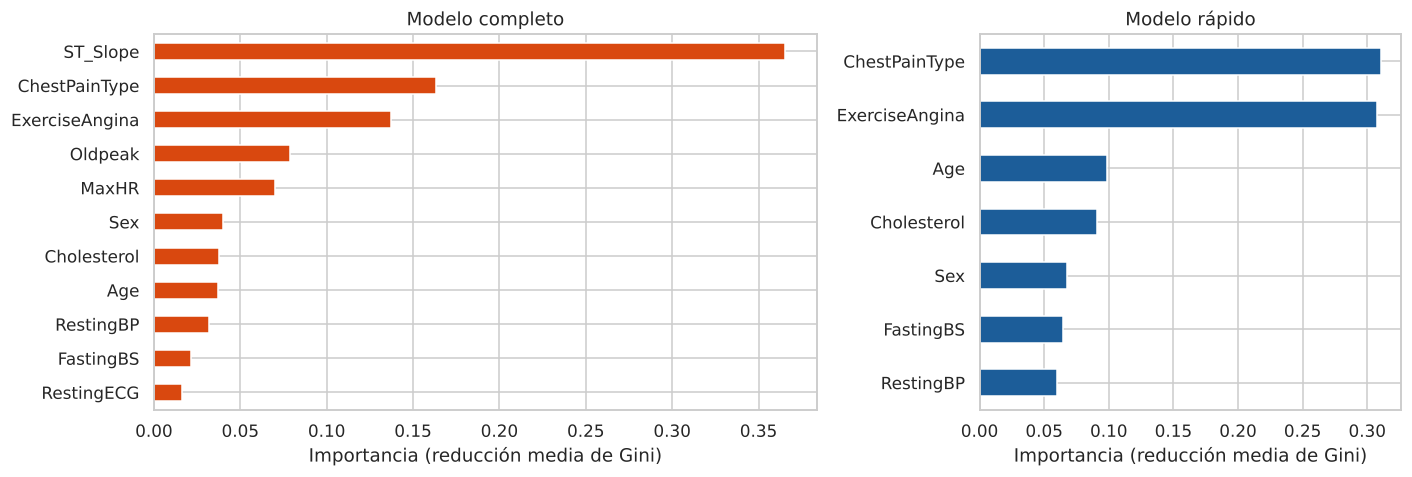

In [17]:
def importancia_por_variable(modelo, feats):
    prep, rf = modelo.named_steps['prep'], modelo.named_steps['rf']
    nombres = prep.get_feature_names_out()
    imp = pd.Series(rf.feature_importances_, index=nombres)
    # Se suman las columnas one-hot de una misma variable original.
    grupo = [next(f for f in feats if n.split('__', 1)[1] == f or n.split('__', 1)[1].startswith(f + '_'))
             for n in nombres]
    return imp.groupby(grupo).sum().sort_values()

imp_full = importancia_por_variable(modelos['completo'], FEATURES_FULL)
imp_quick = importancia_por_variable(modelos['rapido'], FEATURES_QUICK)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [11, 7]})
imp_full.plot.barh(ax=axes[0], color='#d9480f'); axes[0].set_title('Modelo completo')
imp_quick.plot.barh(ax=axes[1], color='#1c5d99'); axes[1].set_title('Modelo rápido')
for ax in axes: ax.set_xlabel('Importancia (reducción media de Gini)')
plt.tight_layout(); plt.savefig(IMG + 'feature_importance.png', bbox_inches='tight'); plt.show()

En el modelo completo dominan **ST_Slope**, **ChestPainType**, **Oldpeak** y **ExerciseAngina**, que son justamente
las variables de la prueba de esfuerzo. Sin ellas, el modelo rápido se apoya en el tipo de dolor, la angina con ejercicio, la edad y el colesterol.

### 5.4 Explicación de una predicción individual

In [18]:
from src.predict import explain

paciente = X_test.iloc[[0]]
base, contrib = explain(modelos['completo'], paciente[FEATURES_FULL], FEATURES_FULL)
proba = modelos['completo'].predict_proba(paciente[FEATURES_FULL])[0, 1]
print(f'Probabilidad base (promedio de entrenamiento): {base:.3f}')
print(f'Base + suma de contribuciones:                 {base + sum(contrib.values()):.3f}')
print(f'predict_proba del modelo:                      {proba:.3f}   (real = {y_test.iloc[0]})')
pd.DataFrame({'valor': paciente[FEATURES_FULL].iloc[0], 'contribución': pd.Series(contrib)}) \
  .sort_values('contribución', key=abs, ascending=False).round(3)

Probabilidad base (promedio de entrenamiento): 0.553
Base + suma de contribuciones:                 0.950
predict_proba del modelo:                      0.950   (real = 1)


,valor,contribución
ST_Slope,Flat,0.134
ExerciseAngina,Y,0.102
ChestPainType,ASY,0.077
MaxHR,113,0.042
Oldpeak,1.5,0.028
Sex,M,0.027
RestingBP,115.0,-0.016
Cholesterol,NaN,0.016
FastingBS,0,-0.009
Age,46,-0.009


La suma de la base más las contribuciones coincide con `predict_proba`. Esta descomposición es la que muestra la app en la página de resultado.

## 6. Serialización del modelo

In [19]:
joblib.dump(modelos['rapido'], '../models/rf_rapido.pkl', compress=3)
joblib.dump(modelos['completo'], '../models/rf_completo.pkl', compress=3)

def limpiar_params(p):
    return {k.replace('rf__', ''): (v if v is not None else 'None') for k, v in p.items()}

metadata = {
    'trained_at': str(date.today()),
    'sklearn_version': sklearn.__version__,
    'dataset': {'n_rows': int(len(df)), 'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
                'positive_rate': round(float(y.mean()) * 100, 1)},
    'models': {n: {'features': FEATS[n], 'params': limpiar_params(busquedas[n].best_params_),
                   'test': {k: round(float(v), 4) for k, v in resultados[n].items() if not k.startswith('cv_')},
                   'cv_accuracy_mean': round(float(resultados[n]['cv_accuracy_mean']), 4),
                   'cv_accuracy_std': round(float(resultados[n]['cv_accuracy_std']), 4)}
               for n in modelos},
}
with open('../models/metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

# Verificación: el modelo cargado desde disco predice igual que el de memoria.
recargado = joblib.load('../models/rf_completo.pkl')
assert (recargado.predict(X_test) == modelos['completo'].predict(X_test[FEATURES_FULL])).all()
print('Modelos guardados y verificados en ../models/')

Modelos guardados y verificados en ../models/


## 7. Conclusiones

- El **modelo completo** obtuvo accuracy de **89.7%**, recall de **93.1%** y ROC-AUC de **0.928** en el conjunto de prueba.
- El **modelo rápido**, sin datos de ECG ni prueba de esfuerzo, obtuvo accuracy de **80.4%**, recall de **80.4%** y ROC-AUC de **0.899**.
- La diferencia (9.2 puntos de accuracy) es el costo de no pedirle al usuario los datos clínicos. A cambio, el modelo rápido lo puede usar cualquier persona respondiendo preguntas sencillas.
- En este problema importa más el **recall** (no dejar pasar a un enfermo) que la precision. Por eso la app muestra la probabilidad con un semáforo en lugar de un sí/no.
- Limitaciones: el dataset tiene 918 pacientes de cinco hospitales de EE. UU. y Europa (décadas de 1980 y 1990), por lo que el modelo no debe usarse para diagnóstico real.